In [1]:
!pip install dask[dataframe]

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, classification_report,
    confusion_matrix, mean_absolute_error, cohen_kappa_score, roc_curve, auc
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random
import pandas as pd

In [3]:
np.random.seed(42)
random.seed(42)

In [4]:
df = pd.read_csv('/content/Feature_selection_2.csv')
df

,Unnamed: 0,FP22,FP80,FP126,FP176,FP198,FP298,FP426,FP437,FP472,...,EStateFP19,EStateFP25,EStateFP28,EStateFP29,EStateFP30,EStateFP32,EStateFP34,EStateFP35,EStateFP36,EStateFP54
0,0,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
1,1,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
2,2,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
3,3,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
4,4,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23912,23912,0,0,0,1,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
23913,23913,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
23914,23914,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
23915,23915,0,0,0,0,0,1,0,0,0,...,0,1,0,1,0,0,0,0,0,0


In [5]:
df = df.drop('Unnamed: 0', axis=1)
X = df.drop(["class"], axis=1)
Y = df["class"]

In [6]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=42)

In [7]:
# Initialize and Train RandomForestClassifier
et = RandomForestClassifier(n_estimators=100, random_state=42)
et.fit(X_train, Y_train)
y_pred = et.predict(X_test)
y_pred_proba = et.predict_proba(X_test)[:, 1]

In [8]:
# Evaluation Metrics
accuracy = accuracy_score(Y_test, y_pred)
auc_score = roc_auc_score(Y_test, y_pred_proba)
clf_report = classification_report(Y_test, y_pred)

In [9]:
# Confusion Matrix
conf_matrix = confusion_matrix(Y_test, y_pred)
sensitivity = conf_matrix[1, 1] / (conf_matrix[1, 0] + conf_matrix[1, 1])
mae = mean_absolute_error(Y_test, y_pred)
kappa = cohen_kappa_score(Y_test, y_pred)

In [10]:
# Print Results
print("RandomForestClassifier Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f}")
print(f"AUC: {auc_score:.4f}")
print(f"Classification Report:\n{clf_report}")
print("\nConfusion Matrix:")
print(conf_matrix)
print(f"\nSensitivity (Recall): {sensitivity:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Cohen's Kappa Score: {kappa:.4f}")

RandomForestClassifier Evaluation Metrics:
Accuracy: 0.9026
AUC: 0.9524
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.96      0.93      4915
           1       0.90      0.77      0.83      2261

    accuracy                           0.90      7176
   macro avg       0.90      0.87      0.88      7176
weighted avg       0.90      0.90      0.90      7176


Confusion Matrix:
[[4725  190]
 [ 509 1752]]

Sensitivity (Recall): 0.7749
Mean Absolute Error (MAE): 0.0974
Cohen's Kappa Score: 0.7654


In [11]:
# ROC Curve Plot
fpr, tpr, _ = roc_curve(Y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

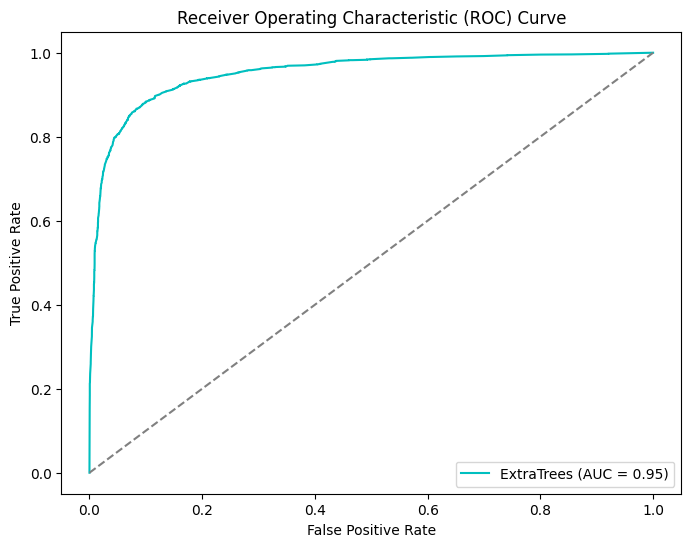

In [12]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='c', label=f'ExtraTrees (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.savefig('roc_curve_RF.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
from sklearn.model_selection import cross_val_score

In [14]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = cross_val_score(et, X, Y, cv=skf, scoring='accuracy')

print(f"Stratified K-Fold Accuracy: {cv_scores}")
print(f"Mean Accuracy: {np.mean(cv_scores)} ± {np.std(cv_scores)}")

Stratified K-Fold Accuracy: [0.90426421 0.91555184 0.90886288 0.91011706 0.90928094 0.90342809
 0.90928094 0.91258887 0.90506064 0.90547888]
Mean Accuracy: 0.9083914351337024 ± 0.0036731213915597214


In [15]:
import pickle

# Save model
with open("randomforest_model.pkl", "wb") as model_file:
    pickle.dump(et, model_file)

# Load model
with open("randomforest_model.pkl", "rb") as model_file:
    loaded_model = pickle.load(model_file)

# Test loaded model
y_pred_loaded = loaded_model.predict(X_test)
print(f"Loaded Model Accuracy: {accuracy_score(Y_test, y_pred_loaded)}")

Loaded Model Accuracy: 0.9025919732441472


In [16]:
import pandas as pd

# Load unknown data
unknown_df = pd.read_excel("/content/FEATURES_UK.xlsx")

In [17]:
# Get the feature names used during training
training_features = loaded_model.feature_names_in_

# Select only the necessary columns from unknown_df, and reorder them
unknown_df = unknown_df.reindex(columns=training_features)

In [18]:
# Predict class labels
predictions = loaded_model.predict(unknown_df)

# Predict probabilities (if needed)
probabilities = loaded_model.predict_proba(unknown_df)

original_unknown_df = pd.read_excel("/content/FEATURES_UK.xlsx")
Names = original_unknown_df["Name"]

# Convert predictions to a DataFrame
predictions_df = pd.DataFrame({
    "Name": Names,
    "Predicted_Class": predictions,
    "Probability_Class_0": probabilities[:, 0],  # Probability of class 0
    "Probability_Class_1": probabilities[:, 1]   # Probability of class 1
})

# Save predictions
predictions_df.to_csv("predictions.csv", index=False)
print("Predictions saved to predictions.csv")

Predictions saved to predictions.csv
